Partie :1

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler
A = pd.read_csv("Titanic-Dataset.csv")
print("Dimensions du dataset :", A.shape)
print("Les premières lignes du dataset :")
display(A.head())
numérique = A.select_dtypes(include="number")
print("Variables numériques :", numérique.columns.tolist())
catégorielle = A.select_dtypes(include="str")
print("Variables catégorielles :", catégorielle.columns.tolist())
print("Les valeurs manquantes :",A.isnull().sum())

Dimensions du dataset : (891, 12)
Les premières lignes du dataset :


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Variables numériques : ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Variables catégorielles : ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']
Les valeurs manquantes : PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


Partie:2

In [2]:
print("pourcentage es valeurs manquantes :\n ",A.isnull().mean()*100)

pourcentage es valeurs manquantes :
  PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64


In [3]:
median_age = A["Age"].median()
print("La médiane de Age est :", median_age)
A["Age"] = A["Age"].fillna(median_age)
mode_embarked = A["Embarked"].mode()[0]
print("Le mode de Embarked est :", mode_embarked)
A["Embarked"] = A["Embarked"].fillna(mode_embarked)
A = A.drop(columns=["Cabin"])
print("les valeurs manquantes aprés le traitement :\n",A.isnull().sum())

La médiane de Age est : 28.0
Le mode de Embarked est : S
les valeurs manquantes aprés le traitement :
 PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


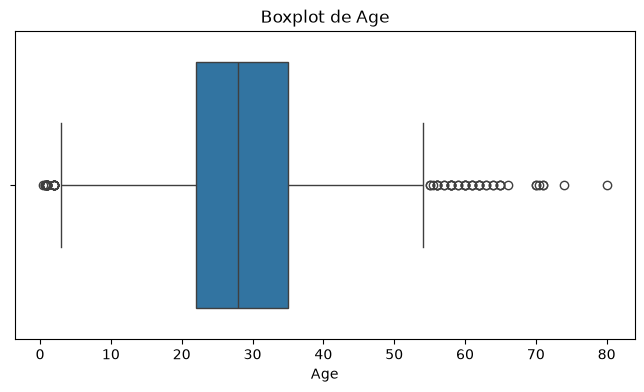

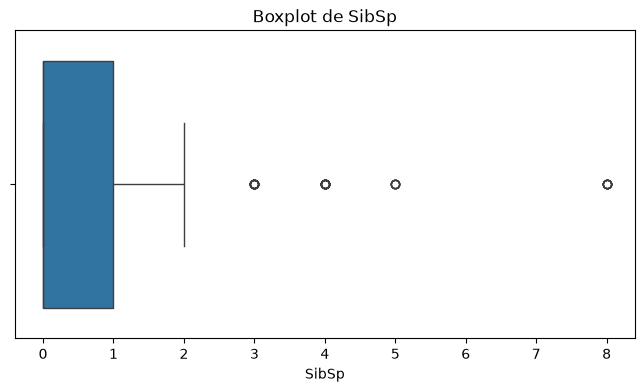

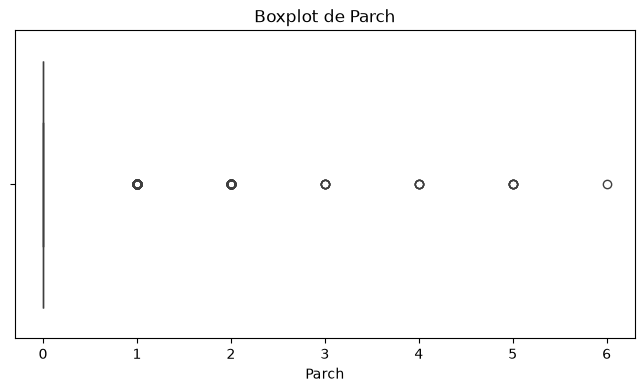

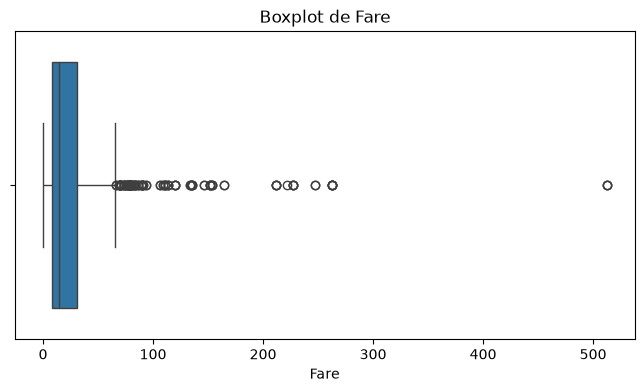

In [4]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=A["Age"])
plt.title("Boxplot de Age")
plt.show()

plt.figure(figsize=(8, 4))
sns.boxplot(x=A["SibSp"])
plt.title("Boxplot de SibSp")
plt.show()

plt.figure(figsize=(8, 4))
sns.boxplot(x=A["Parch"])
plt.title("Boxplot de Parch")
plt.show()

plt.figure(figsize=(8, 4))
sns.boxplot(x=A["Fare"])
plt.title("Boxplot de Fare")
plt.show()

In [5]:
Q1 = A["Age"].quantile(0.25)
Q3 = A["Age"].quantile(0.75)
print("Q1 de Age :", Q1)
print("Q3 de Age :", Q3)

IQR = Q3 - Q1
print("IQR de Age :", IQR )

limite_inférieure = Q1 - 1.5 * IQR
limite_supérieure = Q3 + 1.5 * IQR
print("Limite inférieure :", limite_inférieure)
print("Limite supérieure :", limite_supérieure)

outliers_age = A[(A["Age"] < limite_inférieure)|(A["Age"] > limite_supérieure)]
print("Nombre de valeurs aberrantes dans Age :", len(outliers_age))

mediane_age = A["Age"].median()
print("La médiane de Age est :", mediane_age)

A.loc[(A["Age"] < limite_inférieure)|(A["Age"] > limite_supérieure), "Age"] = mediane_age
print("Outliers Age après traitement :", ((A["Age"] < limite_inférieure)|(A["Age"] > limite_supérieure)).sum()) 


Q1_fare = A["Fare"].quantile(0.25)
Q3_fare = A["Fare"].quantile(0.75)
print("Q1 de Fare :", Q1_fare)
print("Q3 de Fare :", Q3_fare)

IQR_fare = Q3_fare - Q1_fare
print("IQR de Fare :", IQR_fare)

limite_inf_fare = Q1_fare - 1.5 * IQR_fare
limite_sup_fare = Q3_fare + 1.5 * IQR_fare
print("Limite inférieure de Fare :", limite_inf_fare)
print("Limite supérieure de Fare :", limite_sup_fare)

outliers_fare = A[(A["Fare"] < limite_inf_fare)|(A["Fare"] > limite_sup_fare)]
print("Nombre d'Outliers de Fare :", len(outliers_fare))

mediane_fare = A["Fare"].median()
print("La médiane de Fare est :", mediane_fare)

A.loc[(A["Fare"] < limite_inf_fare)|(A["Fare"] > limite_sup_fare), "Fare"] = mediane_fare
print("Outliers Fare après traitement :",((A["Fare"] < limite_inf_fare) |(A["Fare"] > limite_sup_fare)).sum())

Q1_sibsp = A["SibSp"].quantile(0.25)
Q3_sibsp = A["SibSp"].quantile(0.75)
print("Q1 de SibSp :", Q1_sibsp)
print("Q3 de SibSp :", Q3_sibsp)

IQR_sibsp = Q3_sibsp - Q1_sibsp
print("IQR de SibSp :", IQR_sibsp)

limite_inf_sibsp = Q1_sibsp - 1.5 * IQR_sibsp
limite_sup_sibsp = Q3_sibsp + 1.5 * IQR_sibsp
print("Limite inférieure de SibSp :", limite_inf_sibsp)
print("Limite supérieure de SibSp :", limite_sup_sibsp)

outliers_sibsp = A[(A["SibSp"] < limite_inf_sibsp)|(A["SibSp"] > limite_sup_sibsp)]
print("Nombre d'Outliers de SibSp :", len(outliers_sibsp))


Q1_parch = A["Parch"].quantile(0.25)
Q3_parch = A["Parch"].quantile(0.75)
print("Q1 de Parch :", Q1_parch)
print("Q3 de Parch :", Q3_parch)
IQR_parch = Q3_parch - Q1_parch
print("IQR de Parch :", IQR_parch)
limite_inf_parch = Q1_parch - 1.5 * IQR_parch
limite_sup_parch = Q3_parch + 1.5 * IQR_parch
print("Limite inférieure de Parch :", limite_inf_parch)
print("Limite supérieure de Parch :", limite_sup_parch)
outliers_parch = A[(A["Parch"] < limite_inf_parch)|(A["Parch"] > limite_sup_parch)]
print("Nombre d'Outliers de Parch :", len(outliers_parch))

Q1 de Age : 22.0
Q3 de Age : 35.0
IQR de Age : 13.0
Limite inférieure : 2.5
Limite supérieure : 54.5
Nombre de valeurs aberrantes dans Age : 66
La médiane de Age est : 28.0
Outliers Age après traitement : 0
Q1 de Fare : 7.9104
Q3 de Fare : 31.0
IQR de Fare : 23.0896
Limite inférieure de Fare : -26.724
Limite supérieure de Fare : 65.6344
Nombre d'Outliers de Fare : 116
La médiane de Fare est : 14.4542
Outliers Fare après traitement : 0
Q1 de SibSp : 0.0
Q3 de SibSp : 1.0
IQR de SibSp : 1.0
Limite inférieure de SibSp : -1.5
Limite supérieure de SibSp : 2.5
Nombre d'Outliers de SibSp : 46
Q1 de Parch : 0.0
Q3 de Parch : 0.0
IQR de Parch : 0.0
Limite inférieure de Parch : 0.0
Limite supérieure de Parch : 0.0
Nombre d'Outliers de Parch : 213


Partie:3

In [6]:
A = pd.get_dummies(A, columns=["Sex", "Embarked"], dtype=int)

print(A.columns.tolist())
display(A.head())
print("Dimensions :", A.shape)


['PassengerId', 'Survived', 'Pclass', 'Name', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S']


,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,0,1,0,0,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,14.4542,1,0,1,0,0
2,3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,1,0,0,0,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,113803,53.1000,1,0,0,0,1
4,5,0,3,"Allen, Mr. William Henry",35.0,0,0,373450,8.0500,0,1,0,0,1


Dimensions : (891, 14)


In [7]:
colonnes = ["Pclass", "Age", "SibSp", "Parch", "Fare"]

normalisation = MinMaxScaler()
A2 = A.copy()

A2[colonnes] = normalisation.fit_transform(A2[colonnes])

print("Avant normalisation :")
display(A[colonnes].head())

print("Après normalisation :")
display(A2[colonnes].head())

Avant normalisation :


,Pclass,Age,SibSp,Parch,Fare
0,3,22.0,1,0,7.2500
1,1,38.0,1,0,14.4542
2,3,26.0,0,0,7.9250
3,1,35.0,1,0,53.1000
4,3,35.0,0,0,8.0500


Après normalisation :


,Pclass,Age,SibSp,Parch,Fare
0,1.0,0.372549,0.125,0.0,0.111538
1,0.0,0.686275,0.125,0.0,0.222372
2,1.0,0.450980,0.000,0.0,0.121923
3,0.0,0.627451,0.125,0.0,0.816923
4,1.0,0.627451,0.000,0.0,0.123846


In [8]:
standardisation = StandardScaler()

A3 = A.copy()

A3[colonnes] = standardisation.fit_transform(A[colonnes])

print("Avant standardisation :")
display(A[colonnes].head())

print("Après standardisation :")
display(A3[colonnes].head())

Avant standardisation :


,Pclass,Age,SibSp,Parch,Fare
0,3,22.0,1,0,7.2500
1,1,38.0,1,0,14.4542
2,3,26.0,0,0,7.9250
3,1,35.0,1,0,53.1000
4,3,35.0,0,0,8.0500


Après standardisation :


,Pclass,Age,SibSp,Parch,Fare
0,0.827377,-0.661724,0.432793,-0.473674,-0.797554
1,-1.566107,0.972921,0.432793,-0.473674,-0.230556
2,0.827377,-0.253063,-0.474545,-0.473674,-0.744429
3,-1.566107,0.666425,0.432793,-0.473674,2.811012
4,0.827377,0.666425,-0.474545,-0.473674,-0.734591


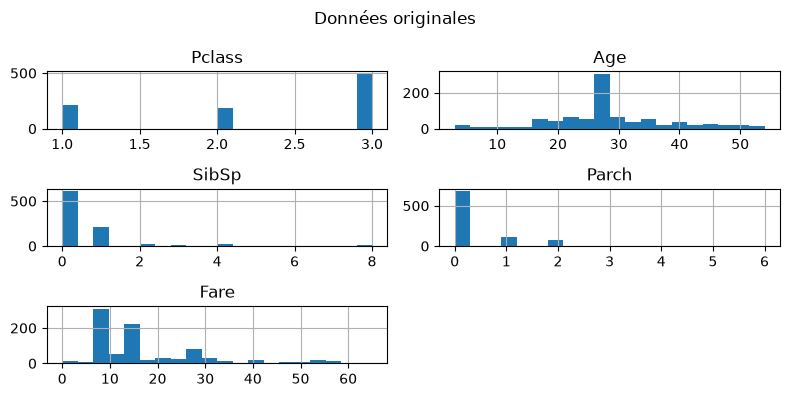

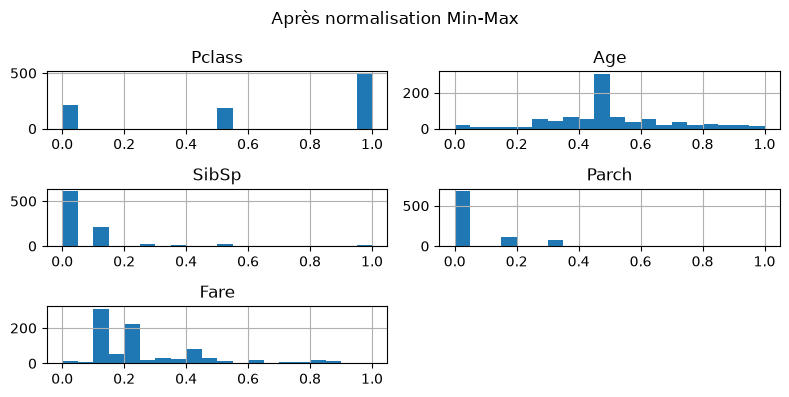

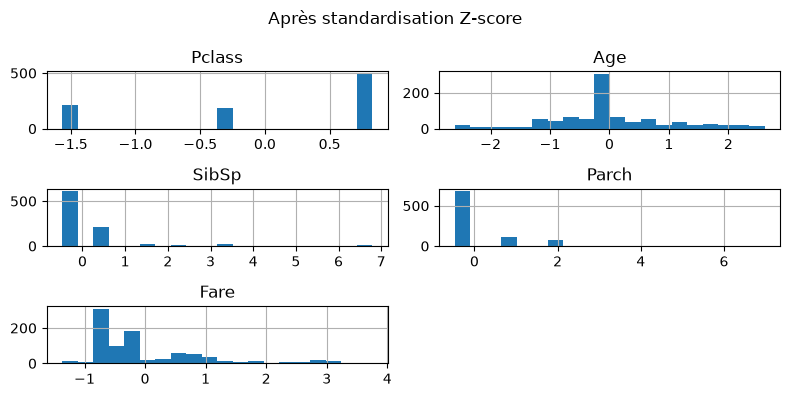

In [9]:
A[colonnes].hist(figsize=(8, 4), bins=20)
plt.suptitle("Données originales")
plt.tight_layout()
plt.show()

A2[colonnes].hist(figsize=(8, 4), bins=20)
plt.suptitle("Après normalisation Min-Max")
plt.tight_layout()
plt.show()

A3[colonnes].hist(figsize=(8, 4), bins=20)
plt.suptitle("Après standardisation Z-score")
plt.tight_layout()
plt.show()

Partie:4

In [10]:
print(A["Survived"].value_counts())
print(A["Survived"].value_counts(normalize=True) * 100)

A0 = A[A["Survived"] == 0]
A1 = A[A["Survived"] == 1]
B = A0.sample(len(A1))
C = pd.concat([B, A1])
print(C["Survived"].value_counts())

Survived
0    549
1    342
Name: count, dtype: int64
Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64
Survived
0    342
1    342
Name: count, dtype: int64


In [11]:
from imblearn.over_sampling import SMOTE

X = A.drop(columns=["Survived", "PassengerId", "Name", "Ticket"])
y = A["Survived"]

smote = SMOTE()
X_smote, y_smote = smote.fit_resample(X, y)

print(y_smote.value_counts())

Survived
0    549
1    549
Name: count, dtype: int64
